# $W_{qk}$ layer 2 — `separate` vs `combined`, with layer 1 pinned

Run: **`qk2only_opt-adam_lr-0.005_b-256_init-normal_ep-500`** (`train_fixing_qk_layer1_and_ov.py`).

Everything except the layer-2 QK circuit is frozen to the hand construction:

| component | state |
|---|---|
| layer 1 $W_{qk}$ | **frozen** $=\sqrt D\,T_1^\top$, identical in both archs |
| layer 1 / layer 2 $W_{ov}$ | **frozen** $=I_8$ at $[0{:}8,\,0{:}8]$ |
| unembedding $W_{out}$ | **frozen** identity selector |
| pre-log bias $b$ | **frozen** $(b_{sig}=0.01,\ b_{noise}=(1-\alpha)/4\alpha)$ |
| **layer 2 $W_{qk}$** | **trainable** — 46,656 parameters in *both* archs |

So this is the cleanest possible comparison: the two architectures have the **same number of free
parameters, in the same place**, and `separate` reaches the layer-2 product through the factors
$W_{qk}=W_Q^\top W_K$ (rank $\le 108$) while `combined` moves the $216\times216$ product directly
(full rank available).

The notebook plots those two learned matrices side by side, at every threshold, against the
construction they are supposed to be reaching.

In [1]:
import os, glob, json, importlib.util
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
SD = D ** 0.5
ALPHA_REC, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9

Wq1 = torch.eye(D) * SD
T1 = torch.zeros(D, D)
for k in range(VS, V):
    T1[k, :] = BIG
for tq in range(T):
    for tk in range(T):
        T1[V + tk, V + tq] = BIG if tq == tk else -ALPHA_REC * (tq - tk)
Wk1 = T1.t()
Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
Wo1 = torch.eye(D)

Wq2 = torch.zeros(D, IN2)
Wq2[:VS, :VS] = torch.eye(VS) * SD * P1
Wq2[:VS, D:D + VS] = torch.eye(VS) * SD * P2
for v in range(V):
    Wq2[VS, v] = SD * NF
Wk2 = torch.zeros(D, IN2); Wk2[:V, D:D + V] = torch.eye(V)
for v in range(VS, V):
    Wk2[VS, v] = GAMMA
Wv2 = torch.zeros(D, IN2); Wv2[:V, :V] = torch.eye(V)
Wo2 = torch.eye(D)

PROD = {'W_qk layer1': Wq1.t() @ Wk1, 'W_ov layer1': Wv1.t() @ Wo1.t(),
        'W_qk layer2': Wq2.t() @ Wk2, 'W_ov layer2': Wv2.t() @ Wo2.t()}

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 11,
                     'axes.titlesize': 12, 'axes.grid': False})
ART = 'artifacts/qk2only_opt-adam_lr-0.005_b-256_init-normal_ep-500'
os.makedirs(ART, exist_ok=True)
print('construction W_qk layer2:', tuple(PROD['W_qk layer2'].shape),
      ' nnz', int((PROD['W_qk layer2'] != 0).sum()),
      f" ||.||_F {float(PROD['W_qk layer2'].norm()):.4g}")

construction W_qk layer2: (216, 216)  nnz 48  ||.||_F 2.939e+07


In [2]:
def bounds(n):
    return [V, D] if n == D else ([V, D, D + V] if n == IN2 else [V])

def show(ax, M, title, lw=0.9):
    A = M.numpy()
    a = np.abs(A[A != 0])
    vmax = float(a.max()) if a.size else 1.0
    norm = SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), linscale=0.6,
                      vmin=-vmax, vmax=vmax, base=10)
    im = ax.imshow(A, cmap='RdBu_r', norm=norm, interpolation='nearest', aspect='equal')
    for b in bounds(A.shape[0]):
        ax.axhline(b - .5, color='k', lw=lw)
    for b in bounds(A.shape[1]):
        ax.axvline(b - .5, color='k', lw=lw)
    ax.set_title(f'{title}   {A.shape[0]}x{A.shape[1]}   nnz {int((A!=0).sum())}   '
                 f'max|.| {vmax:.4g}', fontsize=12)
    ax.set_xlabel('key dim'); ax.set_ylabel('query dim')
    return im

def blocklabels(ax):
    ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_xticklabels(['key tok\n0:8', 'key pos\n8:108', 'key L1 tok\n108:116',
                        'key L1 pos\n116:216'], fontsize=9)
    ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_yticklabels(['q tok\n0:8', 'q pos\n8:108', 'q L1 tok\n108:116',
                        'q L1 pos\n116:216'], fontsize=9, rotation=90, va='center')

def annot(ax, M, r0, r1, c0, c1, title, rlab=None, clab=None, fmt='{:.4g}', fs=8):
    A = M[r0:r1, c0:c1].numpy()
    a = np.abs(A[A != 0]); vmax = float(a.max()) if a.size else 1.0
    ax.imshow(A, cmap='RdBu_r',
              norm=SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), linscale=0.6,
                              vmin=-vmax, vmax=vmax, base=10),
              interpolation='nearest')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, fmt.format(A[i, j]) if A[i, j] != 0 else '.', ha='center',
                    va='center', fontsize=fs, color='#111111')
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_xticklabels(clab if clab else range(c0, c1), fontsize=8)
    ax.set_yticklabels(rlab if rlab else range(r0, r1), fontsize=8)
    ax.set_title(title, fontsize=11)

## 0. Load the run and check what is actually frozen

Before believing any picture, confirm the frozen blocks really are the construction, in *both*
architectures. If any of these is not ~0 the comparison below is meaningless.

In [3]:
CELL  = 'qk2only_opt-adam_lr-0.005_b-256_init-normal_ep-500'
CDIR  = os.path.join('runs', CELL)
ARCHS = ['separate', 'combined']

_s = importlib.util.spec_from_file_location('qk2', 'train_fixing_qk_layer1_and_ov.py')
QK2 = importlib.util.module_from_spec(_s); _s.loader.exec_module(QK2)

THRS = sorted(float(p.split('_x_')[1][:-4])
              for p in glob.glob(os.path.join(CDIR, 'model_separate_*.pth')))

def load(arch, thr):
    m = QK2.QKOnlyTransformer(V, T, D, VS, thr, arch)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_{arch}_seed0_x_{thr}.pth'),
                                 map_location='cpu', weights_only=True))
    return m.eval()

def eff(model):
    qk, ov = [], []
    for layer in (model.layer1, model.layer2):
        if hasattr(layer, 'W_qk'):
            qk.append(layer.W_qk.detach()); ov.append(layer.W_ov.detach())
        else:
            qk.append(layer.W_q.weight.detach().t() @ layer.W_k.weight.detach())
            ov.append(layer.W_v.weight.detach().t() @ layer.W_o.weight.detach().t())
    return qk, ov

QK = {a: {t: eff(load(a, t))[0] for t in THRS} for a in ARCHS}
OV = {a: {t: eff(load(a, t))[1] for t in THRS} for a in ARCHS}
MET = {(a, t): json.load(open(os.path.join(CDIR, f'metrics_{a}_seed0_x_{t}.json')))
       for a in ARCHS for t in THRS}

print(f'cell       {CELL}')
print(f'thresholds {THRS}\n')
print('frozen-block check -- max |learned - construction|')
for t in THRS:
    row = []
    for a in ARCHS:
        d1 = float((QK[a][t][0] - PROD['W_qk layer1']).abs().max())
        d2 = max(float((OV[a][t][i] - PROD[k]).abs().max())
                 for i, k in ((0, 'W_ov layer1'), (1, 'W_ov layer2')))
        row.append(f'{a}: qk1 {d1:.1e}  ov {d2:.1e}')
    print(f'  a={t}   ' + '   |   '.join(row))
print()
print('layer-1 W_qk identical between the two archs:',
      all(torch.equal(QK['separate'][t][0], QK['combined'][t][0]) for t in THRS))

/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


cell       qk2only_opt-adam_lr-0.005_b-256_init-normal_ep-500
thresholds [0.4, 0.6, 0.8, 1.0]

frozen-block check -- max |learned - construction|
  a=0.4   separate: qk1 0.0e+00  ov 0.0e+00   |   combined: qk1 0.0e+00  ov 0.0e+00
  a=0.6   separate: qk1 0.0e+00  ov 0.0e+00   |   combined: qk1 0.0e+00  ov 0.0e+00
  a=0.8   separate: qk1 0.0e+00  ov 0.0e+00   |   combined: qk1 0.0e+00  ov 0.0e+00
  a=1.0   separate: qk1 0.0e+00  ov 0.0e+00   |   combined: qk1 0.0e+00  ov 0.0e+00

layer-1 W_qk identical between the two archs: True


In [4]:
print(f'{"alpha":>6s} | {"separate":^25s} | {"combined":^25s} | {"comb - sep":>12s}')
print(f'{"":>6s} | {"best_train":>12s}{"best_test":>13s} | {"best_train":>12s}{"best_test":>13s} | {"test":>12s}')
print('-' * 80)
for t in THRS:
    s, c = MET[('separate', t)], MET[('combined', t)]
    print(f'{t:6.1f} | {s["best_train"]:12.4f}{s["best_test"]:13.4f} | '
          f'{c["best_train"]:12.4f}{c["best_test"]:13.4f} | '
          f'{c["best_test"] - s["best_test"]:+12.4f}')
print('-' * 80)
gap = np.mean([MET[('combined', t)]['best_test'] - MET[('separate', t)]['best_test'] for t in THRS])
print(f'mean test gap (combined - separate): {gap:+.4f} nats')

 alpha |         separate          |         combined          |   comb - sep
       |   best_train    best_test |   best_train    best_test |         test
--------------------------------------------------------------------------------
   0.4 |       1.8355       1.8376 |       1.8351       1.8387 |      +0.0011
   0.6 |       1.6907       1.6934 |       1.6904       1.6946 |      +0.0012
   0.8 |       1.3776       1.3792 |       1.3772       1.3800 |      +0.0008
   1.0 |       0.7387       0.7412 |       0.7383       0.7419 |      +0.0006
--------------------------------------------------------------------------------
mean test gap (combined - separate): +0.0009 nats


## 1. The side-by-side plot

$W_{qk}$ of **layer 2**, $216\times216$, learned by the two parametrizations at one threshold.
Full matrix, symlog colour scale, **each panel on its own scale** (the two need not be the same
size, and a shared scale would flatten the smaller one).

The black lines cut the stream into its four blocks:
`token 0:8 | position 8:108 | layer-1-out token 108:116 | layer-1-out position 116:216`.
The block that has to work is **rows 0:8 x columns 108:116** — the query's own token against the
key's layer-1 predecessor. That is the induction match.

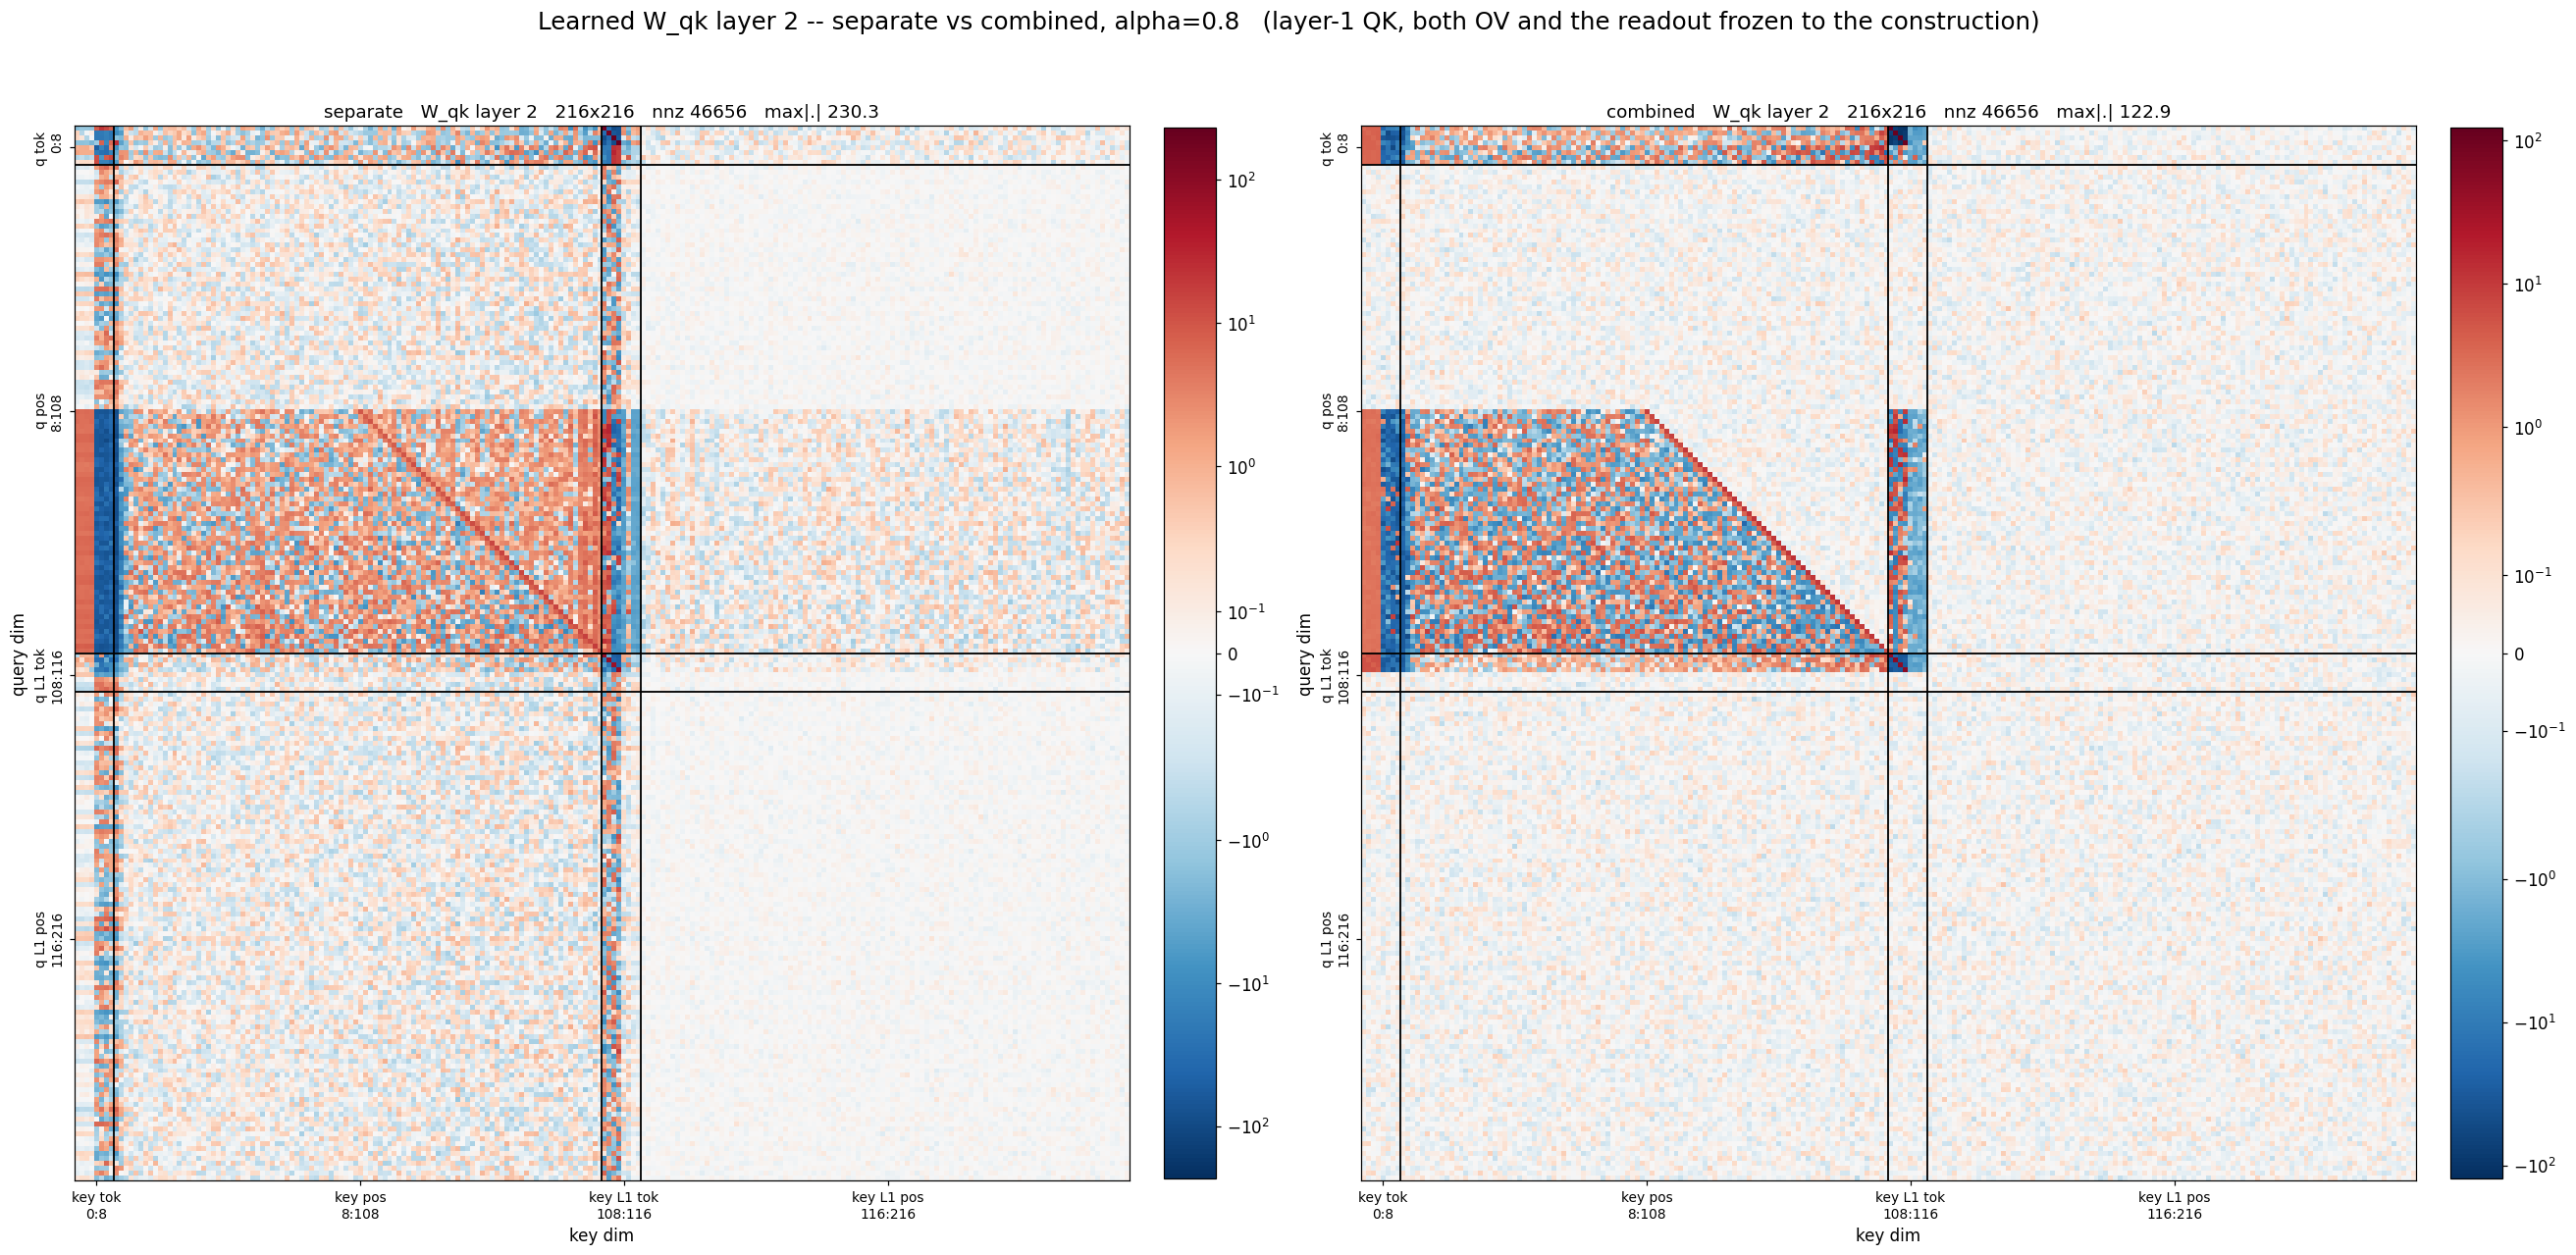

In [5]:
PLOT_THR = 0.8

fig, axes = plt.subplots(1, 2, figsize=(24, 12))
for ax, a in zip(axes, ARCHS):
    im = show(ax, QK[a][PLOT_THR][1], f'{a}   W_qk layer 2', lw=1.2)
    blocklabels(ax)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'Learned W_qk layer 2 -- separate vs combined, alpha={PLOT_THR}   '
             f'(layer-1 QK, both OV and the readout frozen to the construction)', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wqk2_side_by_side_a{PLOT_THR}.png'), bbox_inches='tight')
plt.show()

### 1.1 …with the construction as a third panel

The target. It has **48 non-zeros in 46,656 cells** and its largest entry is $-5.2\times10^6$, so on
its scale the two learned matrices would be invisible — hence, again, per-panel scaling.

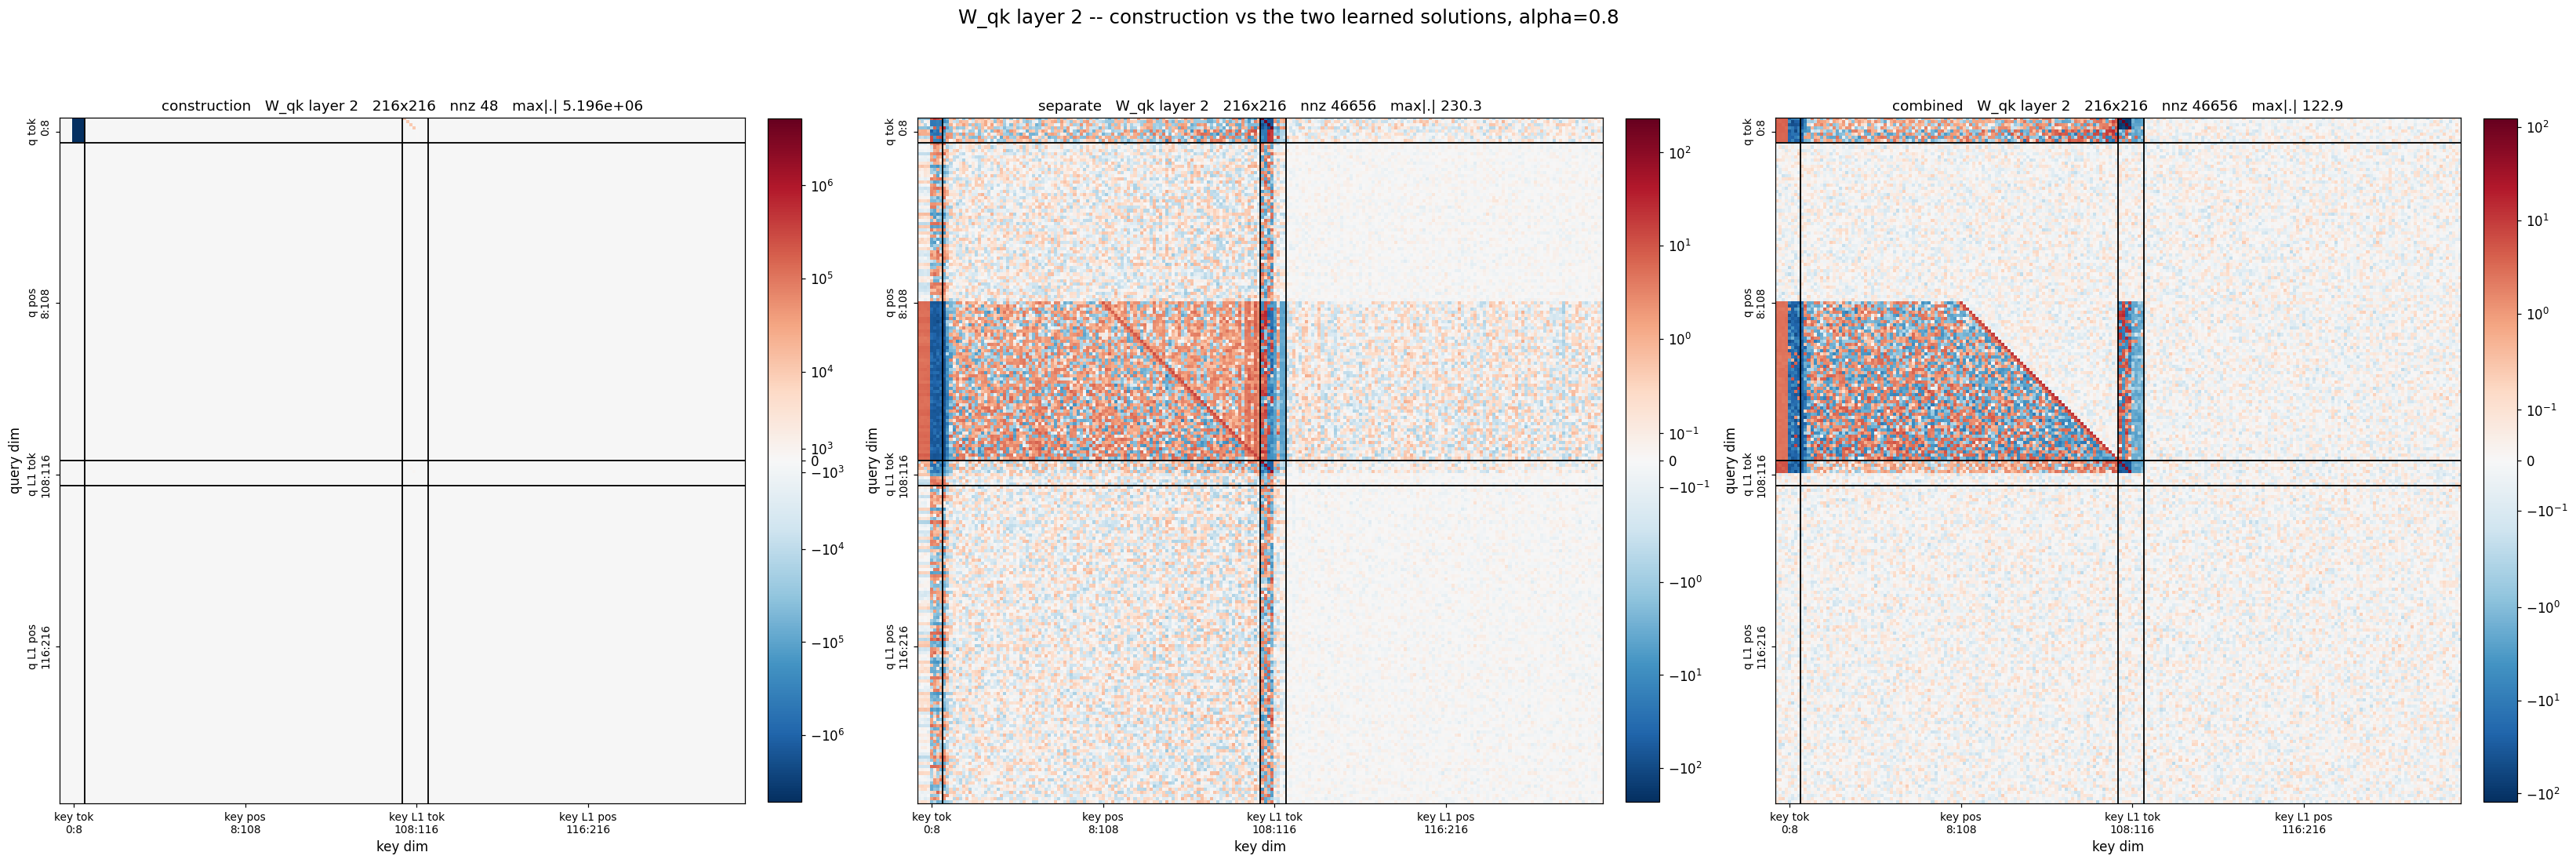

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10.5))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_qk layer2'])] +
                             [(a, QK[a][PLOT_THR][1]) for a in ARCHS]):
    im = show(ax, M, f'{nm}   W_qk layer 2', lw=1.2)
    blocklabels(ax)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'W_qk layer 2 -- construction vs the two learned solutions, alpha={PLOT_THR}',
             fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wqk2_with_construction_a{PLOT_THR}.png'), bbox_inches='tight')
plt.show()

## 2. Every threshold

Two rows (`separate`, `combined`) x four thresholds, per-panel symlog scale.

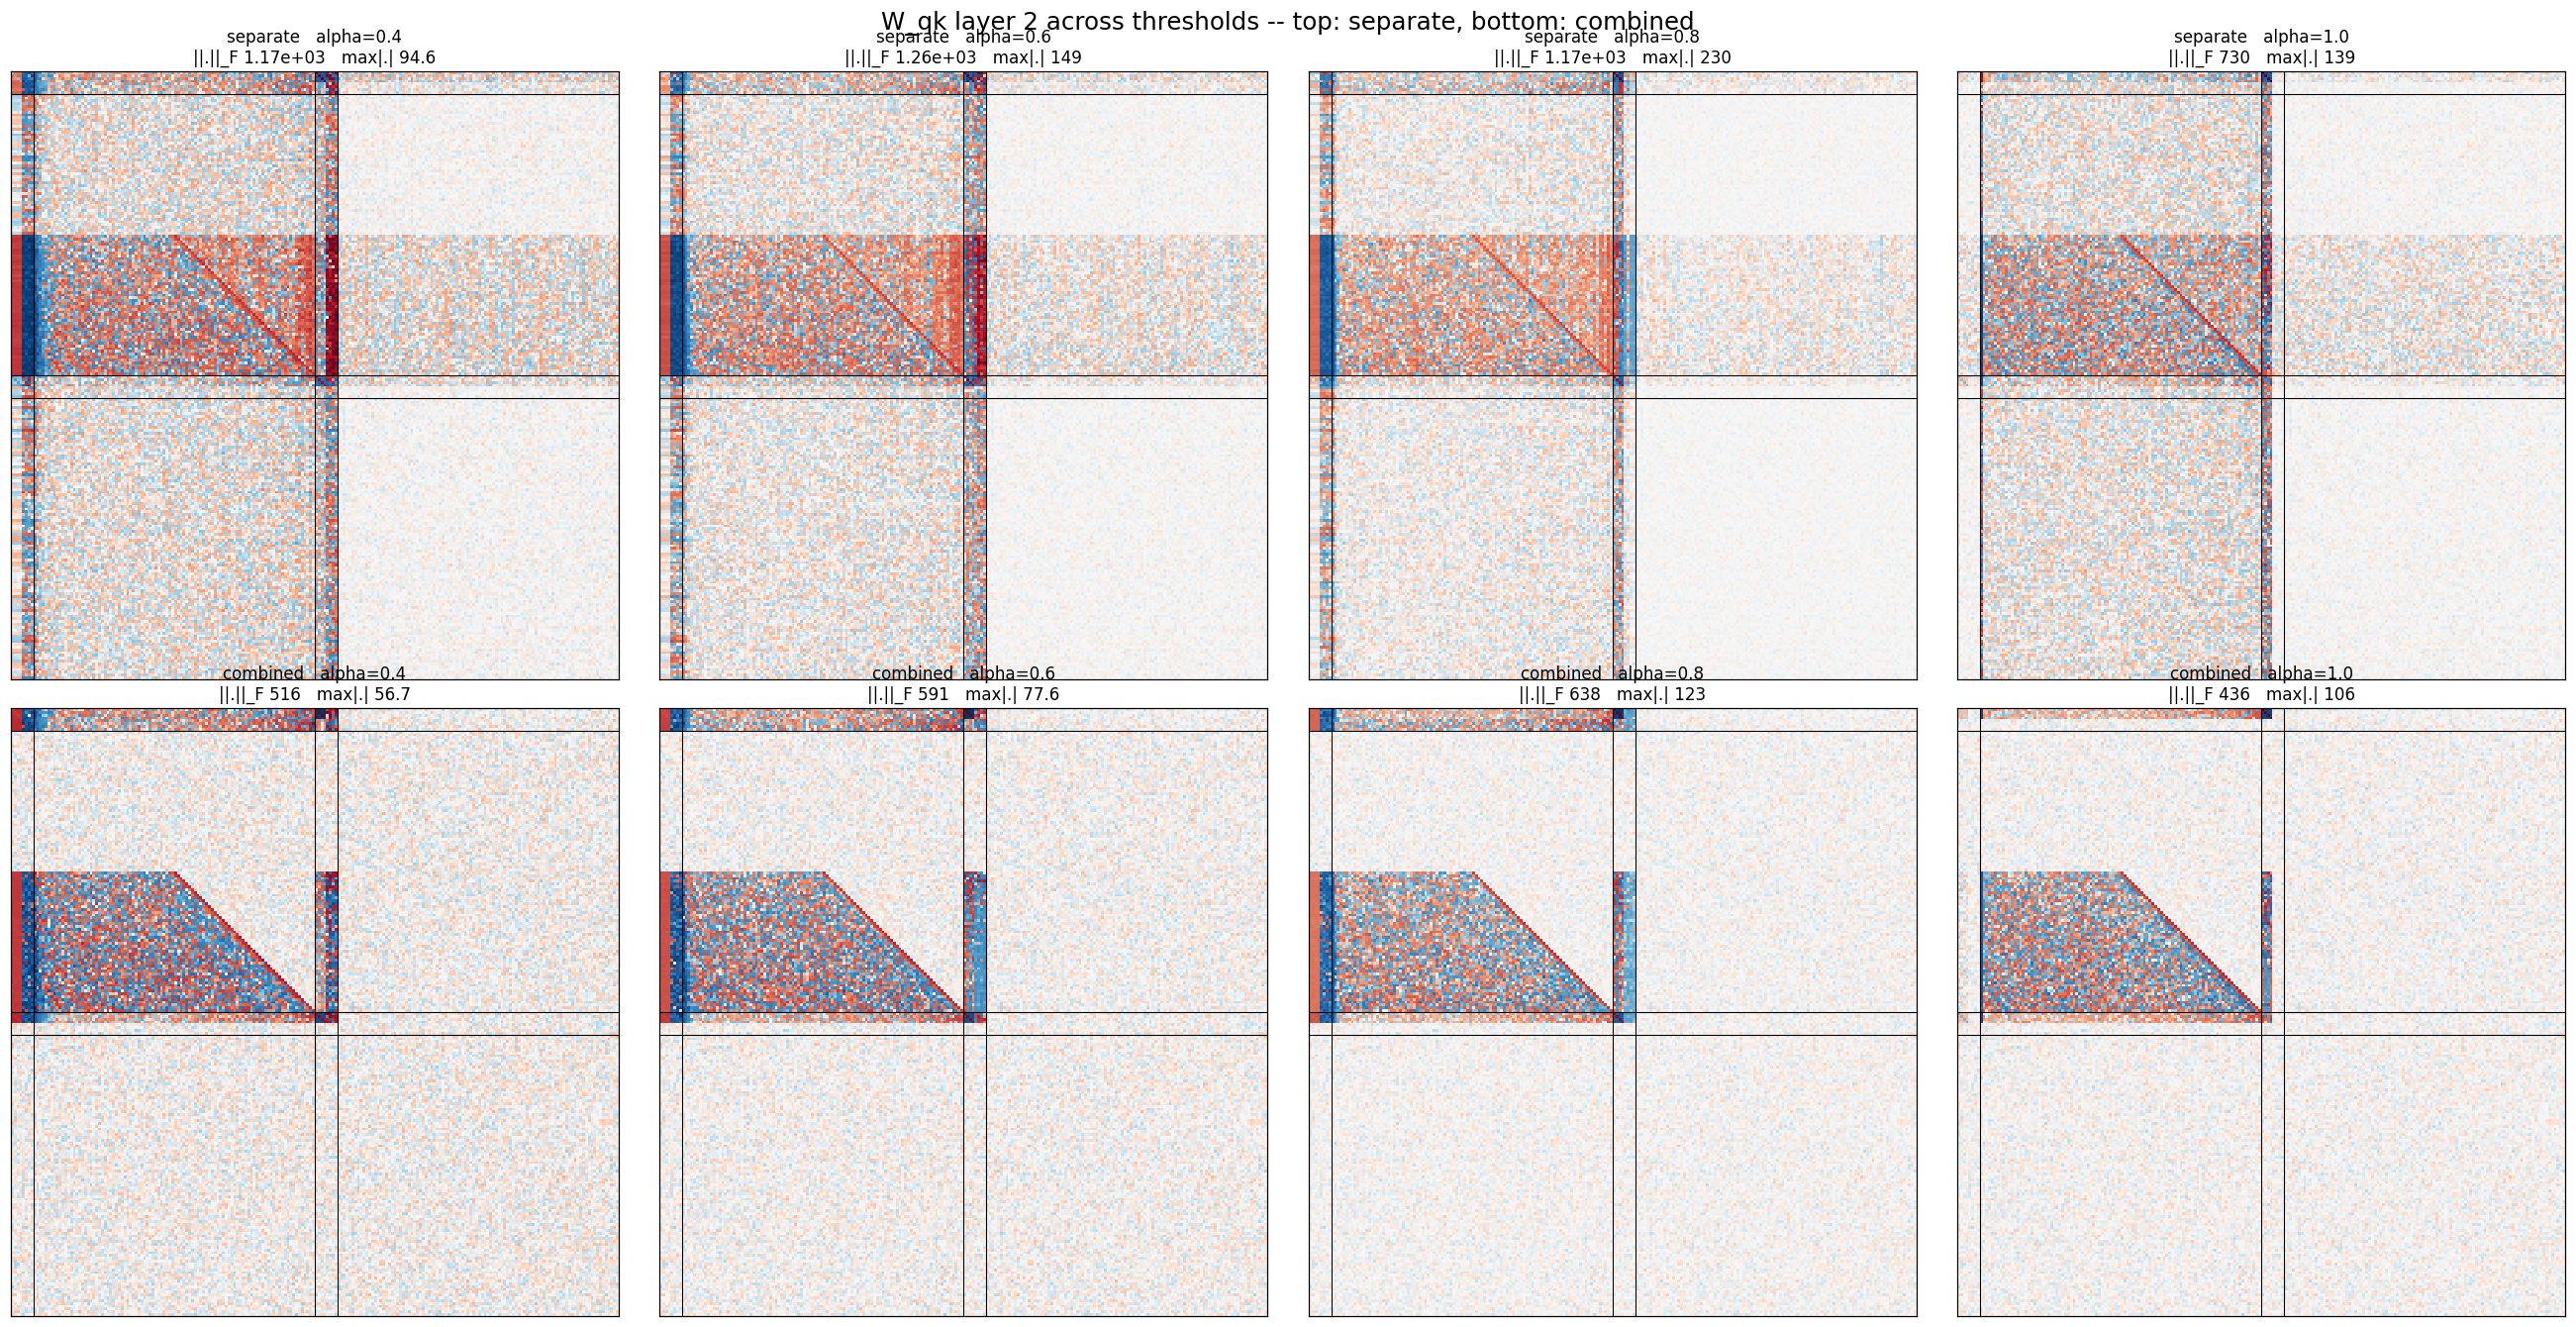

In [7]:
fig, axes = plt.subplots(2, len(THRS), figsize=(6.0 * len(THRS), 12.4))
for j, t in enumerate(THRS):
    for i, a in enumerate(ARCHS):
        ax = axes[i][j]
        M = QK[a][t][1]
        A = M.numpy(); vmax = float(np.abs(A).max()) or 1.0
        ax.imshow(A, cmap='RdBu_r', interpolation='nearest', aspect='equal',
                  norm=SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), linscale=0.6,
                                  vmin=-vmax, vmax=vmax, base=10))
        for b in (V, D, D + V):
            ax.axhline(b - .5, color='k', lw=0.7); ax.axvline(b - .5, color='k', lw=0.7)
        ax.set_title(f'{a}   alpha={t}\n||.||_F {float(M.norm()):.3g}   max|.| {vmax:.3g}',
                     fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('W_qk layer 2 across thresholds -- top: separate, bottom: combined', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'wqk2_all_thresholds.png'), bbox_inches='tight')
plt.show()

## 3. The induction block, cell by cell

Rows `0:8` (query's own token) x columns `108:116` (key's layer-1 predecessor). Every value printed.

In the construction this block is $1000\sqrt D = 10392.3$ on the signal diagonal (rows 0:4) plus the
$10\sqrt D = 103.9$ noise-trigger row at index 4. For the head to do induction, each **signal** row
$v$ must be maximal at column $v$ — that is the whole mechanism. Magnitude matters only as far as
the softmax needs it; the **ordering within a row** is what counts.

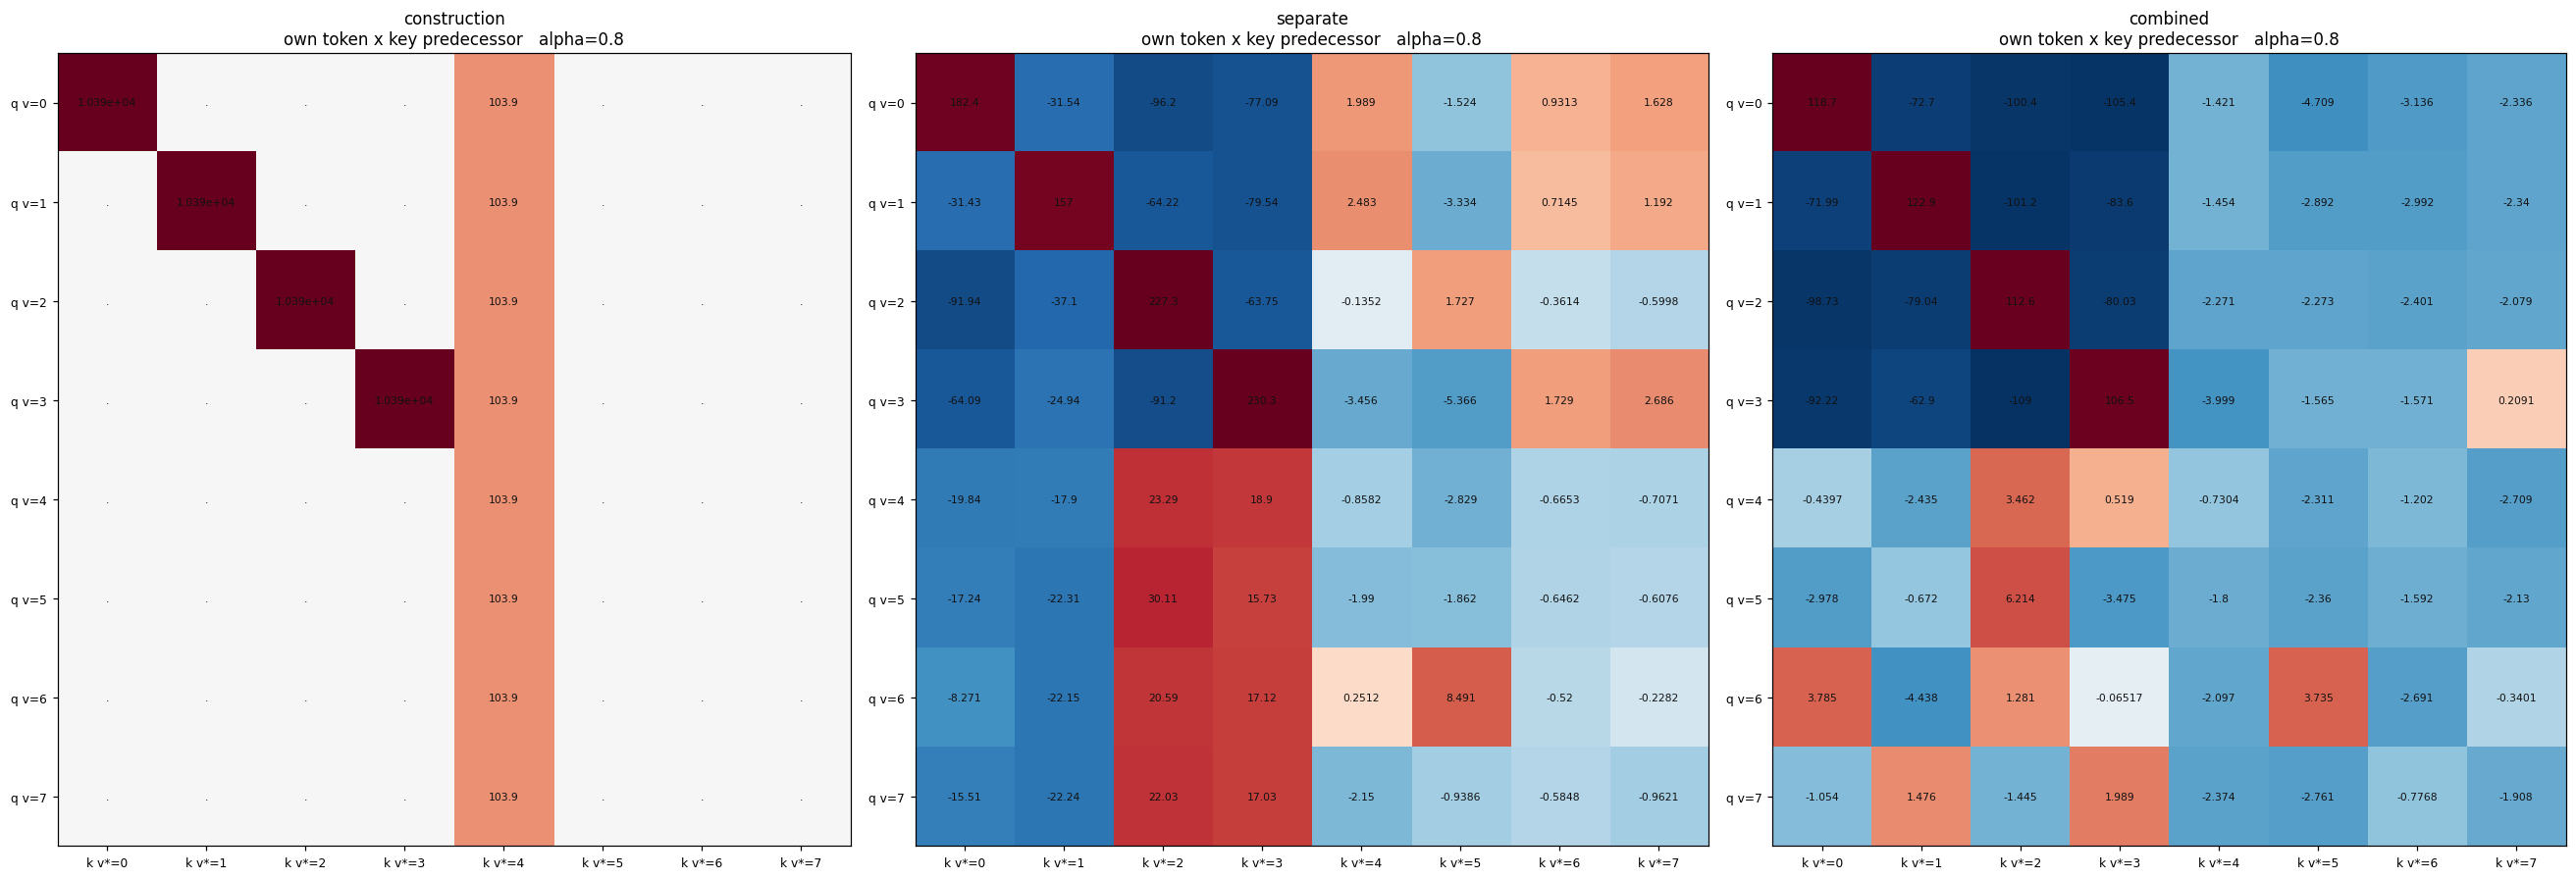

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_qk layer2'])] +
                             [(a, QK[a][PLOT_THR][1]) for a in ARCHS]):
    annot(ax, M, 0, V, D, D + V, f'{nm}\nown token x key predecessor   alpha={PLOT_THR}',
          rlab=[f'q v={i}' for i in range(V)], clab=[f'k v*={i}' for i in range(V)], fs=7)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wqk2_induction_block_a{PLOT_THR}.png'), bbox_inches='tight')
plt.show()

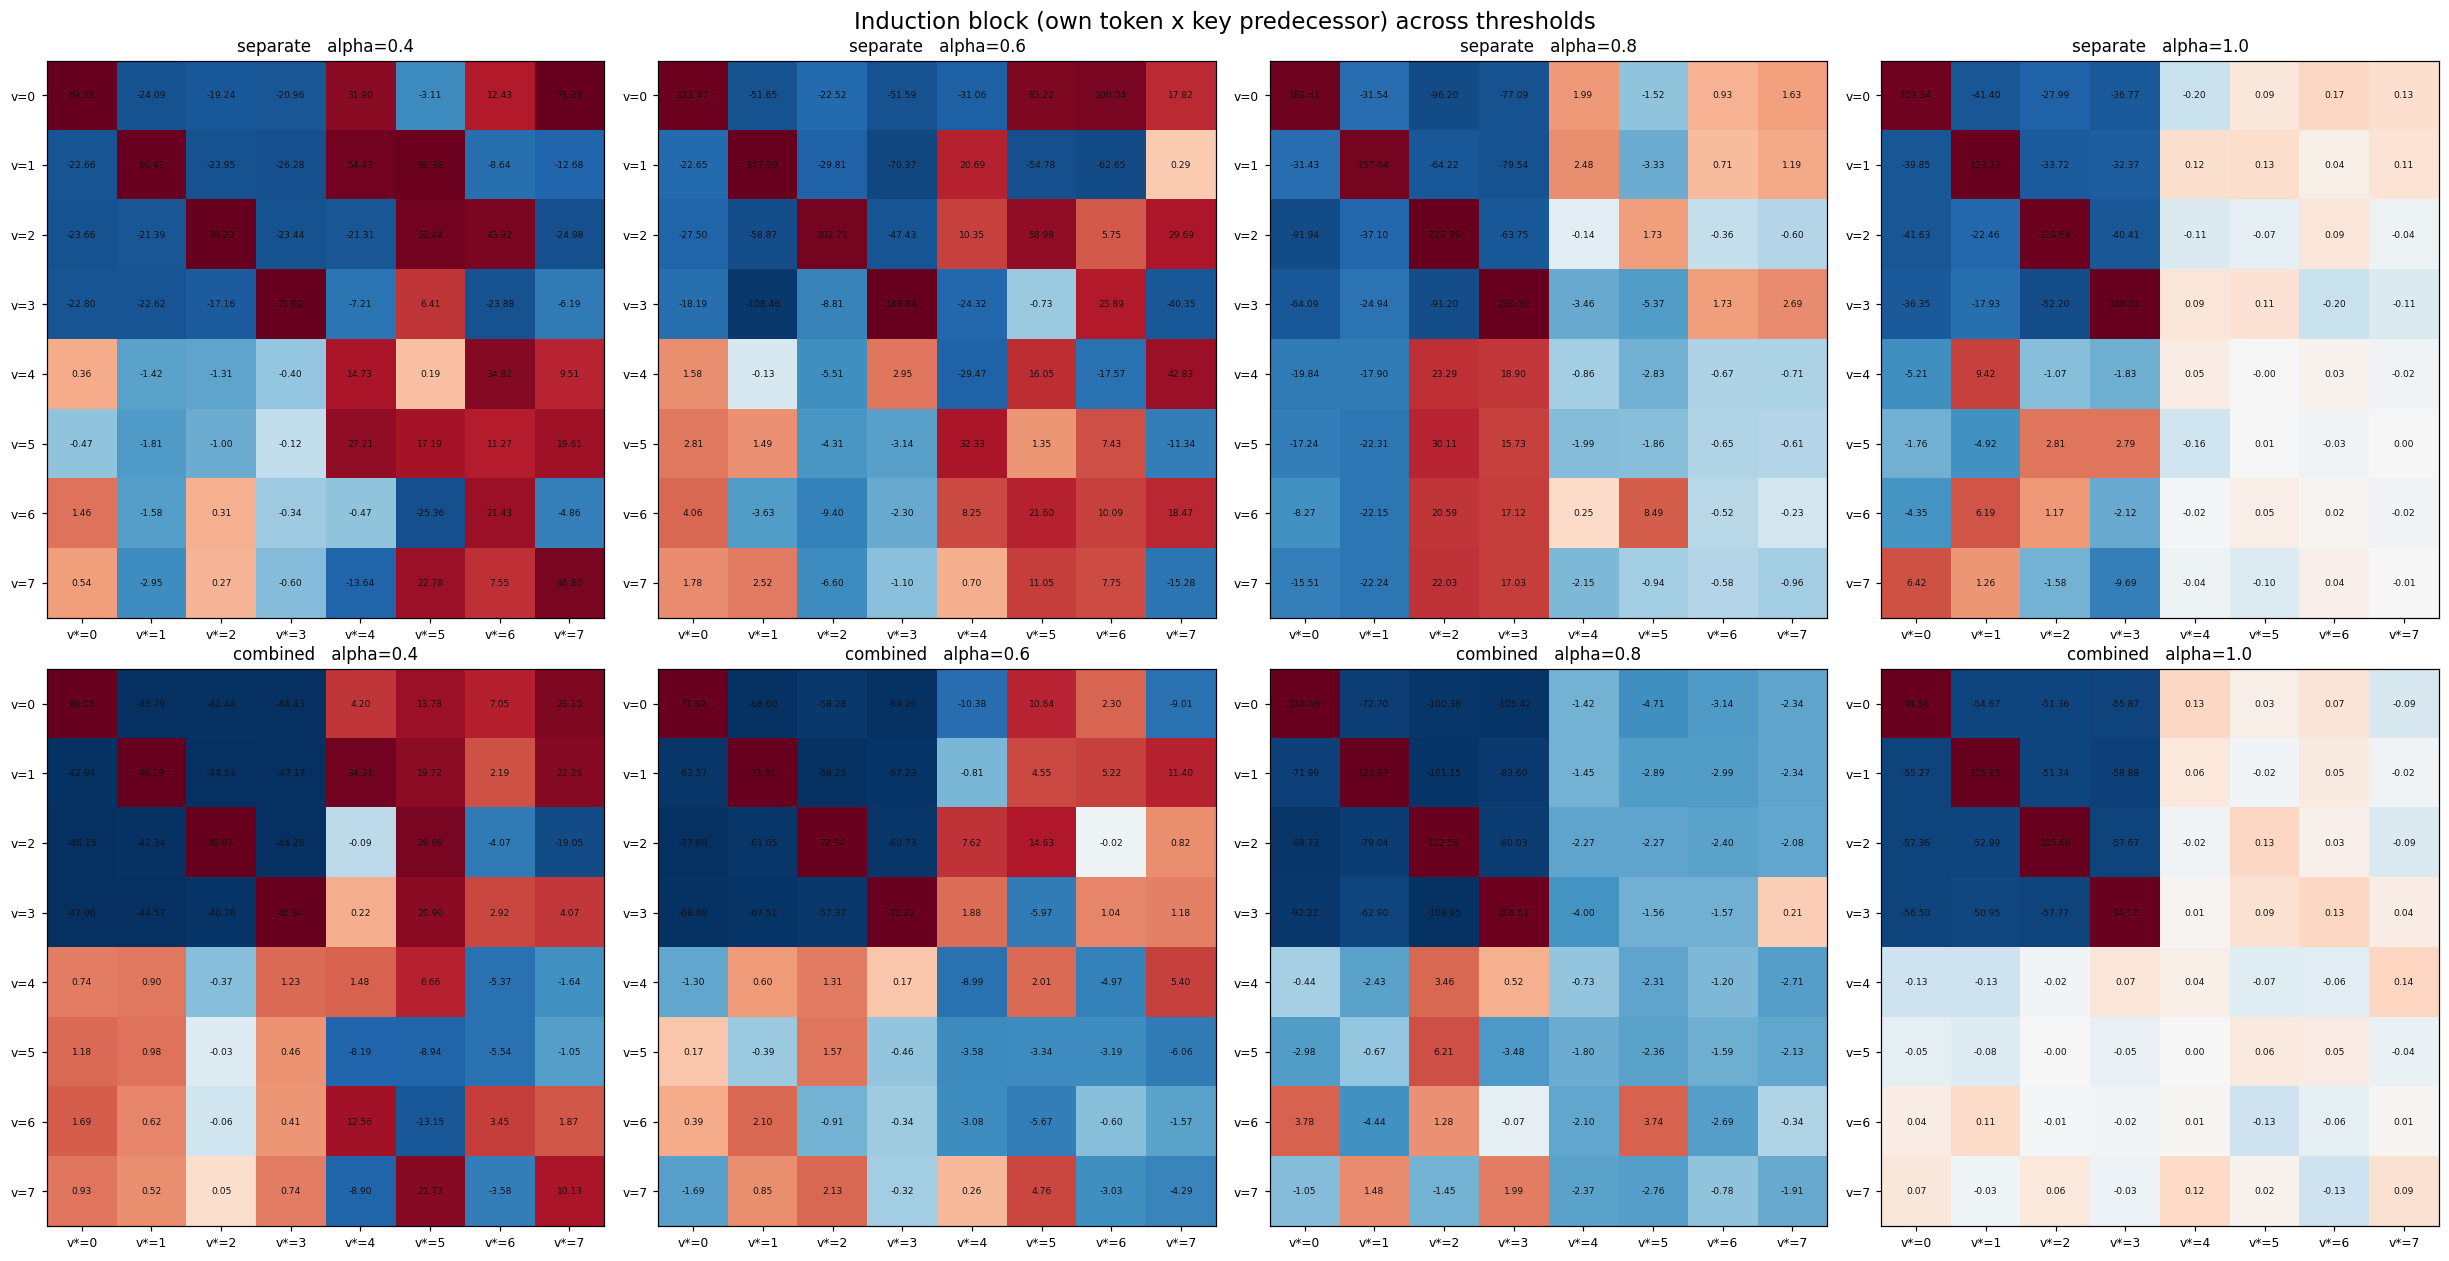

In [9]:
fig, axes = plt.subplots(2, len(THRS), figsize=(5.6 * len(THRS), 11.6))
for j, t in enumerate(THRS):
    for i, a in enumerate(ARCHS):
        annot(axes[i][j], QK[a][t][1], 0, V, D, D + V, f'{a}   alpha={t}',
              rlab=[f'v={k}' for k in range(V)], clab=[f'v*={k}' for k in range(V)],
              fmt='{:.2f}', fs=6)
fig.suptitle('Induction block (own token x key predecessor) across thresholds', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'wqk2_induction_block_all.png'), bbox_inches='tight')
plt.show()

## 4. How close are the two to each other, and to the construction?

Three families of number, all on the layer-2 $W_{qk}$:

* **scale** — $\|W\|_F$ and its ratio to the construction's;
* **similarity** — cosine against the construction and against the other architecture. A raw cosine
  is dominated by whatever bulk offset each solution carries, so a **row-centred** cosine is also
  reported: a softmax score row is invariant to adding a constant across keys, so subtracting each
  row's mean removes a genuine gauge before comparing;
* **does the induction block work** — for the 4 signal rows, whether the argmax over `k v*=0..3`
  sits on the diagonal, and the diagonal's margin over the best off-diagonal entry in the same row
  (absolute, and relative to the block's own spread).

In [10]:
def cos(A, B):
    return float((A * B).sum() / (A.norm() * B.norm()))

def rowcentre(A):
    return A - A.mean(dim=1, keepdim=True)

C = PROD['W_qk layer2']
print(f'{"alpha":>5s} {"arch":>9s} {"||W||_F":>10s} {"/constr":>9s} {"cos constr":>11s} '
      f'{"cos rc":>8s} {"diag hit":>9s} {"min margin":>11s} {"rel":>7s}')
for t in THRS:
    for a in ARCHS:
        M = QK[a][t][1]
        blk = M[:VS, D:D + VS]
        diag = blk.diag()
        off = blk.clone(); off.fill_diagonal_(float('-inf'))
        margin = diag - off.max(dim=1).values
        hit = float((blk.argmax(dim=1) == torch.arange(VS)).float().mean())
        print(f'{t:5.1f} {a:>9s} {float(M.norm()):10.4g} {float(M.norm() / C.norm()):9.2e} '
              f'{cos(M, C):11.3f} {cos(rowcentre(M), rowcentre(C)):8.3f} {hit:9.2f} '
              f'{float(margin.min()):11.4g} '
              f'{float((margin / (blk.max() - blk.min())).min()):7.3f}')

print()
print(f'{"alpha":>5s} {"cos(sep,comb)":>14s} {"cos rc":>9s} {"||sep-comb||_F / ||sep||_F":>29s}')
for t in THRS:
    S, K = QK['separate'][t][1], QK['combined'][t][1]
    print(f'{t:5.1f} {cos(S, K):14.3f} {cos(rowcentre(S), rowcentre(K)):9.3f} '
          f'{float((S - K).norm() / S.norm()):29.3f}')

alpha      arch    ||W||_F   /constr  cos constr   cos rc  diag hit  min margin     rel
  0.4  separate       1173  3.99e-05       0.110    0.110      1.00       88.18   0.906
  0.4  combined      515.8  1.75e-05       0.206    0.205      1.00        87.1   0.931
  0.6  separate       1258  4.28e-05       0.074    0.074      1.00       130.2   0.506
  0.6  combined      590.5  2.01e-05       0.203    0.201      1.00       128.6   0.849
  0.8  separate       1170  3.98e-05       0.046    0.046      1.00       188.5   0.577
  0.8  combined      638.4  2.17e-05       0.188    0.184      1.00       169.4   0.731
  1.0  separate      729.9  2.48e-05       0.001    0.001      1.00       137.3   0.718
  1.0  combined      436.4  1.48e-05       0.001   -0.001      1.00       145.1   0.881

alpha  cos(sep,comb)    cos rc    ||sep-comb||_F / ||sep||_F
  0.4          0.601     0.603                         0.815
  0.6          0.682     0.683                         0.761
  0.8          0.783    

### 4.1 Rank — the one structural difference left

`separate` factors $W_{qk}=W_Q^\top W_K$ with $W_Q,W_K \in \mathbb{R}^{108\times216}$, so its
layer-2 product can never exceed **rank 108** of a possible 216. `combined` has no such ceiling.
The frozen construction has rank 5 there, so the ceiling should not bind — this checks whether it
does.

In [11]:
print(f'{"alpha":>5s} {"arch":>9s} {"rank(1e-4)":>11s}   top-8 singular values')
for t in THRS:
    for a in ARCHS:
        M = QK[a][t][1]
        sv = torch.linalg.svdvals(M.double())
        r = int((sv > 1e-4 * sv[0]).sum())
        print(f'{t:5.1f} {a:>9s} {r:11d}   ' + ' '.join(f'{float(v):.3g}' for v in sv[:8]))
sv = torch.linalg.svdvals(C.double())
print(f'{"":5s} {"constr":>9s} {int((sv > 1e-4 * sv[0]).sum()):11d}   '
      + ' '.join(f'{float(v):.3g}' for v in sv[:8]))

alpha      arch  rank(1e-4)   top-8 singular values
  0.4  separate         108   1.06e+03 221 197 179 152 127 119 109
  0.4  combined         212   341 147 122 117 108 103 101 94.3
  0.6  separate         108   1.1e+03 345 265 184 176 157 140 111
  0.6  combined         211   395 177 165 162 142 118 115 105
  0.8  separate         108   989 357 353 235 127 108 97.5 90.8
  0.8  combined         211   380 246 237 211 143 121 106 87
  1.0  separate         108   592 240 210 195 63.7 56.6 49.3 48.7
  1.0  combined         213   242 174 169 161 61 54.1 50.1 48.3
         constr           5   2.94e+07 1.04e+04 1.04e+04 1.04e+04 7.37e+03 2.29e-09 1.08e-09 3.5e-10


## 5. Notes